In [2]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

df = pd.read_csv("data/water-potability.csv")

df.info()

<class 'pandas.DataFrame'>
RangeIndex: 3276 entries, 0 to 3275
Data columns (total 10 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   ph               2785 non-null   float64
 1   Hardness         3276 non-null   float64
 2   Solids           3276 non-null   float64
 3   Chloramines      3276 non-null   float64
 4   Sulfate          2495 non-null   float64
 5   Conductivity     3276 non-null   float64
 6   Organic_carbon   3276 non-null   float64
 7   Trihalomethanes  3114 non-null   float64
 8   Turbidity        3276 non-null   float64
 9   Potability       3276 non-null   int64  
dtypes: float64(9), int64(1)
memory usage: 256.1 KB


In [3]:
df["Potability"].value_counts()

Potability
0    1998
1    1278
Name: count, dtype: int64

In [6]:
df.isnull().sum()

ph                 491
Hardness             0
Solids               0
Chloramines          0
Sulfate            781
Conductivity         0
Organic_carbon       0
Trihalomethanes    162
Turbidity            0
Potability           0
dtype: int64

In [9]:
df.head()

,ph,Hardness,Solids,Chloramines,Sulfate,Conductivity,Organic_carbon,Trihalomethanes,Turbidity,Potability
0,7.080795,204.890455,20791.318981,7.300212,368.516441,564.308654,10.379783,86.990970,2.963135,0
1,3.716080,129.422921,18630.057858,6.635246,333.775777,592.885359,15.180013,56.329076,4.500656,0
2,8.099124,224.236259,19909.541732,9.275884,333.775777,418.606213,16.868637,66.420093,3.055934,0
3,8.316766,214.373394,22018.417441,8.059332,356.886136,363.266516,18.436524,100.341674,4.628771,0
4,9.092223,181.101509,17978.986339,6.546600,310.135738,398.410813,11.558279,31.997993,4.075075,0


### Wypełnienie braków w danych

In [8]:
df["ph"] = df["ph"].fillna(df["ph"].mean())
df["Sulfate"] = df["Sulfate"].fillna(df["Sulfate"].mean())
df["Trihalomethanes"] = df["Trihalomethanes"].fillna(df["Trihalomethanes"].mean())

df.isnull().sum()

ph                 0
Hardness           0
Solids             0
Chloramines        0
Sulfate            0
Conductivity       0
Organic_carbon     0
Trihalomethanes    0
Turbidity          0
Potability         0
dtype: int64

### Skalowanie MinMax

In [25]:
from sklearn.preprocessing import MinMaxScaler

COLUMNS = ["ph", "Hardness", "Solids", "Chloramines", "Sulfate", "Conductivity", "Organic_carbon", "Trihalomethanes", "Turbidity"]

minmax = MinMaxScaler()
df_minmax = df.copy()
df_minmax[COLUMNS] = minmax.fit_transform(
    df_minmax[COLUMNS]
)
df_minmax[COLUMNS].head()

,ph,Hardness,Solids,Chloramines,Sulfate,Conductivity,Organic_carbon,Trihalomethanes,Turbidity
0,0.505771,0.571139,0.336096,0.543891,0.680385,0.669439,0.313402,0.699753,0.286091
1,0.265434,0.297400,0.300611,0.491839,0.581699,0.719411,0.497319,0.450999,0.576793
2,0.578509,0.641311,0.321619,0.698543,0.581699,0.414652,0.562017,0.532866,0.303637
3,0.594055,0.605536,0.356244,0.603314,0.647347,0.317880,0.622089,0.808065,0.601015
4,0.649445,0.484851,0.289922,0.484900,0.514545,0.379337,0.358555,0.253606,0.496327


### Skalowanie Standard

In [23]:
from sklearn.preprocessing import StandardScaler

COLUMNS = ["ph", "Hardness", "Solids", "Chloramines", "Sulfate", "Conductivity", "Organic_carbon", "Trihalomethanes", "Turbidity"]

standard = StandardScaler()
df_standard = df.copy()
df_standard[COLUMNS] = standard.fit_transform(
    df_standard[COLUMNS]
)
df_standard[COLUMNS].head()

,ph,Hardness,Solids,Chloramines,Sulfate,Conductivity,Organic_carbon,Trihalomethanes,Turbidity
0,-6.043133e-16,0.259195,-0.139471,0.112415,9.613574e-01,1.708954,-1.180651,1.306149,-1.286298
1,-2.289339e+00,-2.036414,-0.385987,-0.307694,3.145987e-15,2.062575,0.270597,-0.638480,0.684218
2,6.928678e-01,0.847665,-0.240047,1.360594,3.145987e-15,-0.094032,0.781117,0.001509,-1.167365
3,8.409504e-01,0.547651,0.000493,0.592008,6.395190e-01,-0.778830,1.255134,2.152874,0.848412
4,1.368569e+00,-0.464429,-0.460249,-0.363698,-6.541765e-01,-0.343939,-0.824357,-2.181599,0.138786


### Wyszukanie wartości odstających

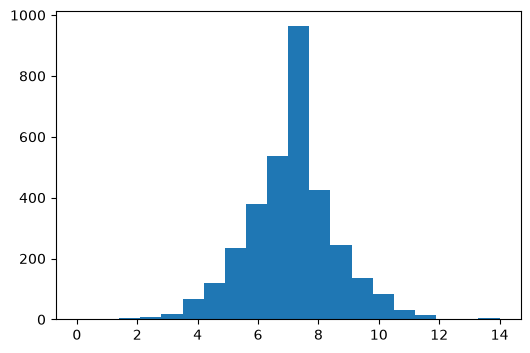

In [ ]:
Q1 = df["ph"].quantile(0.25)
Q3 = df["ph"].quantile(0.75)
IQR = Q3 - Q1
lower = Q1 - 1.5 * IQR
upper = Q3 + 1.5 * IQR
outliers = df[(df["ph"] < lower) | (df["ph"] > upper)]

plt.figure(figsize=(6,4))
plt.hist(df["ph"], bins=20)
plt.show()

### Macierz korelacji

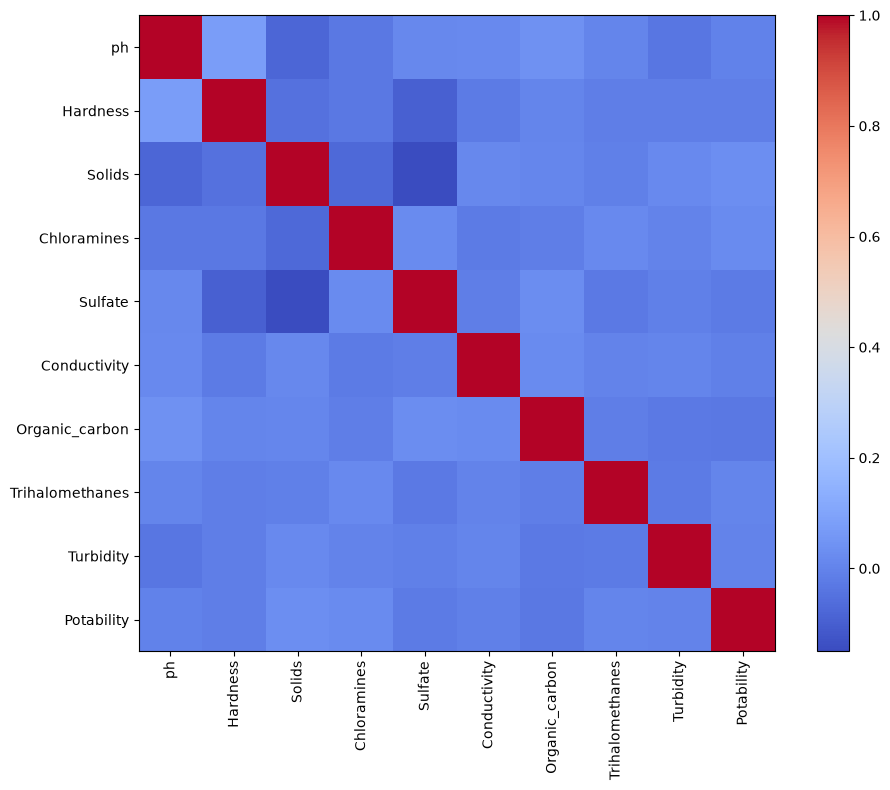

In [18]:
corr = df.select_dtypes(include=np.number).corr()
plt.figure(figsize=(10,8))
plt.imshow(corr, cmap="coolwarm", interpolation="nearest")
plt.colorbar()
plt.xticks(range(len(corr.columns)), corr.columns, rotation=90) # type: ignore
plt.yticks(range(len(corr.columns)), corr.columns) # type: ignore
plt.tight_layout()
plt.show()

### Wybór parametrów

In [19]:
X = df.drop(columns=["Potability"])
X = X.select_dtypes(include=[np.number])
y = df["Potability"]

from sklearn.feature_selection import SelectKBest, f_classif

selector = SelectKBest(score_func=f_classif, k=5)
X_selected = selector.fit_transform(X, y)
selected_features = X.columns[selector.get_support()]
selected_features

Index(['Hardness', 'Solids', 'Chloramines', 'Sulfate', 'Organic_carbon'], dtype='str')

In [20]:
final_df = pd.concat(
    [pd.DataFrame(X_selected, columns=selected_features), y.reset_index(drop=True)],
    axis=1,
)
X = final_df.drop(columns=["Potability"])
y = final_df["Potability"]

In [21]:
X.head()

,Hardness,Solids,Chloramines,Sulfate,Organic_carbon
0,204.890455,20791.318981,7.300212,368.516441,10.379783
1,129.422921,18630.057858,6.635246,333.775777,15.180013
2,224.236259,19909.541732,9.275884,333.775777,16.868637
3,214.373394,22018.417441,8.059332,356.886136,18.436524
4,181.101509,17978.986339,6.546600,310.135738,11.558279


In [22]:
y.value_counts()

Potability
0    1998
1    1278
Name: count, dtype: int64

## Podsumowanie

3 kolumny miały wybrakowane dane, wstawiono tam średnie wartości ze zbioru

